<div style="background-color: steelblue; padding: 10px; border-radius: 5px;">
    <p style="margin: 10;"></p>
    <h1 style="text-align: center; margin: 0; font-weight: bold; color: white;">SWOT OMIP : Seasonality ratio</h1>
    <p style="margin: 10;"></p>
</div>


## 📦**Imports** 

In [1]:
%%time

##################################
#Imports

from datetime import datetime
import s3fs
import xarray as xr
import pyinterp
from widetrax import DataPreprocessing as dp
from widetrax import Spectra as sp
import numpy as np
import json
from watermark import watermark
import time
import platform
from shapely.geometry import shape, box

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
#from widetrax import Spectra as sp
#import plot_psd1Xglobal1 as pp2X
import cum_sp_onl_season_v3 as cs
import importlib

importlib.reload(cs)
import position_function as pf
importlib.reload(pf)

CPU times: user 2.24 s, sys: 545 ms, total: 2.78 s
Wall time: 3.75 s


<module 'position_function' from '/Users/contrema/Documents/Postdoc/SWOTv2/position_function.py'>

## **Map plot functions**

In [2]:
# Function for plot slope
def plot_fig(ax,imodel,lon_edges,lat_edges,ZW,valmin,valmax,model,posx,posy,abc):
    ax[posx,posy].add_feature(cfeature.COASTLINE)
    ax[posx,posy].add_feature(cfeature.LAND, facecolor="lightgray")
    mesh = ax[posx,posy].contourf(
        lon_edges,
        lat_edges,
        np.squeeze((ZW[imodel,:,:])),
        np.arange(valmin,valmax,0.25),
        cmap='hsv',
        transform=ccrs.PlateCarree()
    )
    ax[posx,posy].set_title(abc + model[imodel])
    ax[posx,posy] = ax[posx,posy].gridlines(draw_labels=True,linewidth=0.2)
    ax[posx,posy].bottom_labels = True
    ax[posx,posy].top_labels = False
    ax[posx,posy].right_labels = False
    ax[posx,posy].left_labels = True
    ax[posx,posy].xlines = False
    ax[posx,posy].ylines = False
    return ax, mesh

In [3]:
# Function for plot ratio slope


def plot_fig2v(ax,imodel,lon_edges,lat_edges,ZW,ZS,valmin,valmax,model,posx,posy,abc,box_pos,box_neg):
    #norm = mcolors.LogNorm(vmin=valmin, vmax=valmax)

    ax[posx,posy].add_feature(cfeature.COASTLINE)
    ax[posx,posy].add_feature(cfeature.LAND, facecolor="lightgray")
    mesh = ax[posx,posy].pcolormesh(
        lon_edges,
        lat_edges,
        np.squeeze((ZW[imodel,:,:])/(ZS[imodel,:,:])),
        vmin=valmin,vmax=valmax,
        cmap='seismic',
        transform=ccrs.PlateCarree()
    )
    ax[posx,posy].text(30, 60,f"Boxes >1: {box_pos[imodel]}",transform=ccrs.PlateCarree(),fontsize=8,fontweight='bold',
                      bbox=dict(facecolor='white', alpha=0.6, edgecolor='none'))
    ax[posx,posy].text(30, 40,f"Boxes <1: {box_neg[imodel]}",transform=ccrs.PlateCarree(),fontsize=8,fontweight='bold',
                      bbox=dict(facecolor='white', alpha=0.6, edgecolor='none'))
    ax[posx,posy].set_title(abc + model[imodel])
    ax[posx,posy] = ax[posx,posy].gridlines(draw_labels=True,linewidth=0.2)
    ax[posx,posy].bottom_labels = True
    ax[posx,posy].top_labels = False
    ax[posx,posy].right_labels = False
    ax[posx,posy].left_labels = True
    ax[posx,posy].xlines = False
    ax[posx,posy].ylines = False
    return ax, mesh

## **Load boxes position**

In [4]:
boxesjson="mostly_ocean_boxes_filtered.geojson"
north_boxes, south_boxes=pf.position_boxes_northsouth(boxesjson) # selection of northern and southern hemisphere boxes
selected=pf.position_boxes(boxesjson) # Index boxes for global ocean, and the region



North boxes: 93
South boxes: 189


## **Estimation slope**

In [5]:
#Define Wavelength range
min_wavelength=50
max_wavelength=150
models=["GLO12V4","GLO36V1","GLO36V1NOTIDE","NOC12","NOC025",'LLC4320',"SWOT"]

# Estimation slope, m(s)_slopeW and m(s)_slopeS is the mean (std) slope for winter and summer respectivelu
m_slopeW,m_slopeS,s_slopeW,s_slopeS=cs.season_slope(models,selected,min_wavelength,max_wavelength,north_boxes,south_boxes,
                                                    "https://minio.dive.edito.eu/","JFM","JAS", modeload="online",
                                                    folder="project-meom-ige/OMIP/Global/")

# Reorganizing array (1D) into a map (2D)
m_slopeW2,m_slopeS2=cs.remap(m_slopeW,m_slopeS,models)
s_slopeW2,s_slopeS2=cs.remap(s_slopeW,s_slopeS,models)
#Ver otras escalars



/Users/contrema/Documents/Postdoc/SWOTv2/cum_sp_onl_season_v3.py:133: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJFM)


## **Plotting**
  

In [6]:
# Estimating how many boxes are >/< to 1
box_pos=np.zeros((7))
box_neg=np.zeros((7))

for imodel in range(7):
    box_neg[imodel]=len(np.where(m_slopeW2[imodel,:,:]/m_slopeS2[imodel,:,:]<1)[0])
    box_pos[imodel]=len(np.where(m_slopeW2[imodel,:,:]/m_slopeS2[imodel,:,:]>1)[0])


print(box_pos)
print(box_neg)


[ 70. 116. 114.  83. 155. 148. 116.]
[212. 166. 168. 199. 127. 134. 166.]


/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_41240/2592502517.py:58: RuntimeWarning: Mean of empty slice
  ax[3,0].plot(lat_edges[:-1],np.nanmean(m_slopeW2[i,:,:],axis=1).T,label=model[i],color=colors[i],linestyle=lsty[i])
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_41240/2592502517.py:71: RuntimeWarning: Mean of empty slice
  ax[3,1].plot(lat_edges[:-1],np.nanmean(m_slopeS2[i,:,:],axis=1).T,label=model[i],color=colors[i],linestyle=lsty[i])


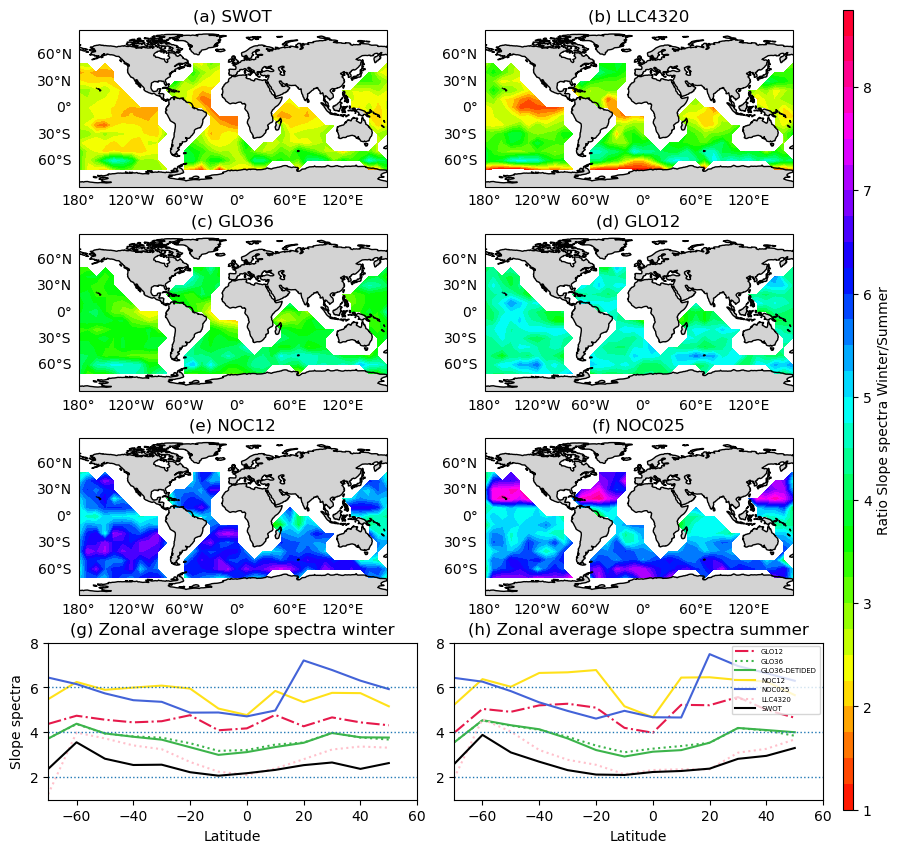

In [7]:
# Plotting  winter slope + zonal averaged of winter and summer slope
#--------------------
# DEFNITION
#--------------------------
model= ["GLO12","GLO36","GLO36-DETIDED","NOC12","NOC025","LLC4320","SWOT"]
#colors = ["#E6194B", "#3CB44B",  "#FFE119", "#4363D8",  "pink", "k", "#3CB44B"]
#lsty=['dashed','dotted','solid','solid','dotted','solid','solid']
lsty=['dashdot','dotted','solid','solid','solid','dotted','solid','solid']

colors = [ "#E6194B", "#3CB44B", "#3CB44B", "#FFE119",  "#4363D8",  "pink", "k"]        #"#F58231",  # orange
        #
#-------------------------
lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)

valmin=1
valmax=9

lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)
lon_edges2,lat_edges2 = np.meshgrid(lon_edges[:-1],lat_edges[:-1])

fig = plt.figure(figsize=(10, 10))
fig.subplots_adjust(wspace=0.1, hspace=0.3)

ax = np.empty((4, 2), dtype=object)

for r in range(4):
    for c in range(2):
        idx = r * 2 + c + 1

        if r < 3:  # first two rows are maps
            ax[r, c] = fig.add_subplot(
                4, 2, idx,
                projection=ccrs.PlateCarree()
            )
        else:      # last two rows are regular axes
            ax[r, c] = fig.add_subplot(4, 2, idx)
            
imodel=6
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,0,0,'(a) ')
imodel=5
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,0,1,'(b) ')
imodel=1
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,1,0,'(c) ')
imodel=0
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,1,1,'(d) ')
imodel=3
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,2,0,'(e) ')
imodel=4
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,2,1,'(f) ')

#plt.colorbar(mesh, ax=ax[0,0], orientation="vertical")
cbar_ax = fig.add_axes([0.92, 0.1, 0.01, .8])
cbar = fig.colorbar(mesh,cax=cbar_ax, orientation='vertical', fraction=0.02,  extend='both')
cbar.set_label("Ratio Slope spectra Winter/Summer")

for i in range(len(colors)):
    ax[3,0].plot(lat_edges[:-1],np.nanmean(m_slopeW2[i,:,:],axis=1).T,label=model[i],color=colors[i],linestyle=lsty[i])
#ax[3,0].plot(lat_edges[:-1],np.nanmean(m_slopeW2,axis=2).T,label=model,color=colors)
ax[3,0].set_xlabel("Latitude")
ax[3,0].set_ylabel("Slope spectra")
ax[3,0].set_title('(g) Zonal average slope spectra winter')
ax[3,0].set_ylim([1,8])
ax[3,0].set_xlim([-70,60])
ax[3,0].axhline(y=2, linestyle=':', linewidth=1)
ax[3,0].axhline(y=4, linestyle=':', linewidth=1)
ax[3,0].axhline(y=6, linestyle=':', linewidth=1)
#ax[3,1].plot(lat_edges[:-1],np.nanmean(m_slopeS2,axis=2).T,label=model,color=colors)

for i in range(len(colors)):
    ax[3,1].plot(lat_edges[:-1],np.nanmean(m_slopeS2[i,:,:],axis=1).T,label=model[i],color=colors[i],linestyle=lsty[i])
ax[3,1].set_title('(h) Zonal average slope spectra summer')
ax[3,1].set_xlabel("Latitude")
ax[3,1].legend(loc='upper right', handlelength=3, fontsize=5)
ax[3,1].set_ylim([1,8])
ax[3,1].set_xlim([-70,60])
ax[3,1].axhline(y=2, linestyle=':', linewidth=1)
ax[3,1].axhline(y=4, linestyle=':', linewidth=1)
ax[3,1].axhline(y=6, linestyle=':', linewidth=1)
#plt.savefig("FigV2/winterslope_season_zonalaverage_V2_{}-{}.png".format(min_wavelength,max_wavelength),dpi=300,transparent=False)
plt.show()



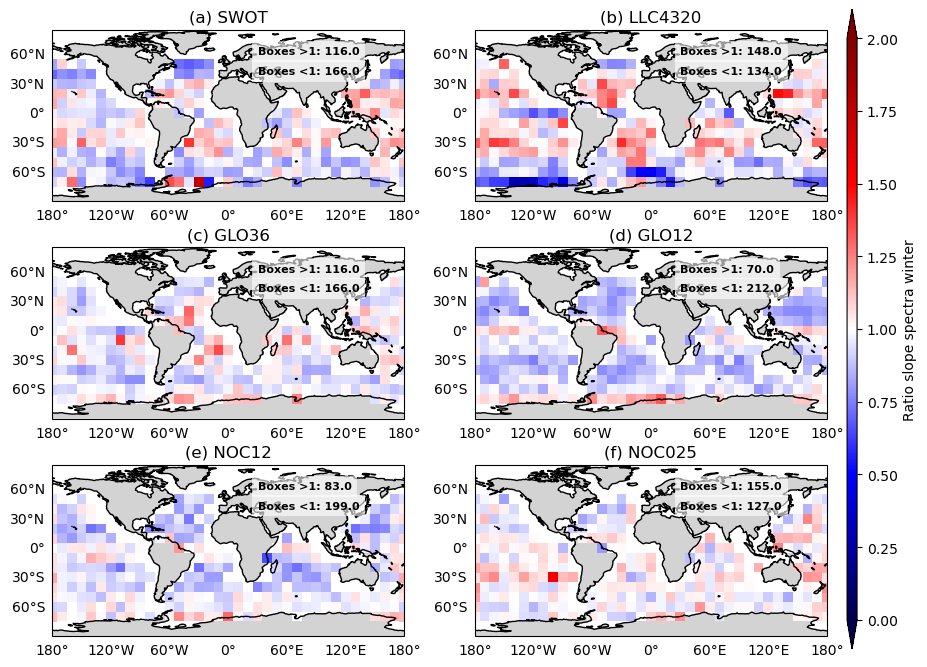

In [11]:
# plotiong seasonal ratio of slope
model= ["GLO12","GLO36","GLO36-DETIDED","NOC12","NOC025","LLC4320","SWOT"]

lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)
lon_edges2,lat_edges2 = np.meshgrid(lon_edges[:-1],lat_edges[:-1])

valmin=0
valmax=2
fig, ax = plt.subplots(3, 2,figsize=(10, 8),subplot_kw={'projection': ccrs.PlateCarree()})
fig.subplots_adjust(wspace=0.2, hspace=0.2)
#ax = plt.axes(projection=ccrs.PlateCarree())
imodel=6
ax, mesh=plot_fig2v(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,m_slopeS2,valmin,valmax,model,0,0,'(a) ',box_pos,box_neg)
imodel=5
ax, mesh=plot_fig2v(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,m_slopeS2,valmin,valmax,model,0,1,'(b) ',box_pos,box_neg)
imodel=1
ax, mesh=plot_fig2v(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,m_slopeS2,valmin,valmax,model,1,0,'(c) ',box_pos,box_neg)
imodel=0
ax, mesh=plot_fig2v(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,m_slopeS2,valmin,valmax,model,1,1,'(d) ',box_pos,box_neg)
imodel=3
ax, mesh=plot_fig2v(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,m_slopeS2,valmin,valmax,model,2,0,'(e) ',box_pos,box_neg)
imodel=4
ax, mesh=plot_fig2v(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,m_slopeS2,valmin,valmax,model,2,1,'(f) ',box_pos,box_neg)



#plt.colorbar(mesh, ax=ax[0,0], orientation="vertical")
cbar_ax = fig.add_axes([0.92, 0.1, 0.01, .8])
cbar = fig.colorbar(mesh,cax=cbar_ax, orientation='vertical', fraction=0.03,  extend='both')
cbar.set_label("Ratio slope spectra winter")
#plt.savefig("FigV2/ratioslope_season_model_{}-{}.png".format(min_wavelength,max_wavelength),dpi=300,transparent=False)
plt.show()



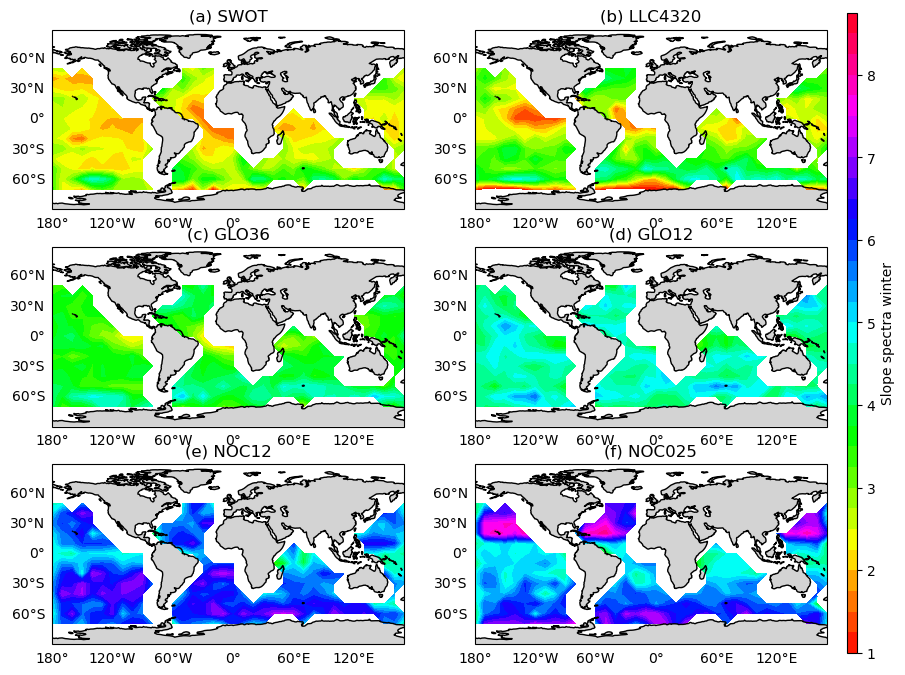

In [12]:
# plotiong seasonal winter mean slope

model= ["GLO12","GLO36","GLO36-DETIDED","NOC12","NOC025","LLC4320","SWOT"]
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)
lon_edges2,lat_edges2 = np.meshgrid(lon_edges[:-1],lat_edges[:-1])

valmin=1
valmax=9
fig, ax = plt.subplots(3, 2,figsize=(10, 8),subplot_kw={'projection': ccrs.PlateCarree()})
fig.subplots_adjust(wspace=0.2, hspace=0.2)
#ax = plt.axes(projection=ccrs.PlateCarree())
imodel=6
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,0,0,'(a) ')
imodel=5
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,0,1,'(b) ')
imodel=1
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,1,0,'(c) ')
imodel=0
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,1,1,'(d) ')
imodel=3
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,2,0,'(e) ')
imodel=4
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeW2,valmin,valmax,model,2,1,'(f) ')



#plt.colorbar(mesh, ax=ax[0,0], orientation="vertical")
cbar_ax = fig.add_axes([0.92, 0.1, 0.01, .8])
cbar = fig.colorbar(mesh,cax=cbar_ax, orientation='vertical', fraction=0.03,  extend='both')
cbar.set_label("Slope spectra winter")
#plt.savefig("FigV2/slope_season_model_winter_{}-{}.png".format(min_wavelength,max_wavelength),dpi=300,transparent=False)
plt.show()



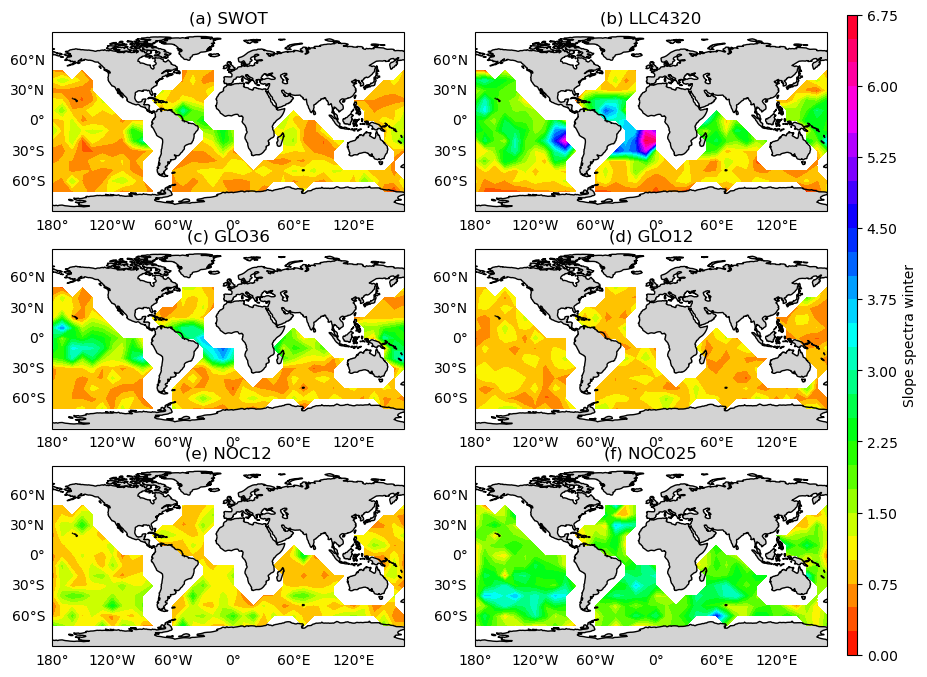

In [13]:
# plotiong seasonal winter std slope

model= ["GLO12","GLO36","GLO36-DETIDED","NOC12","NOC025","LLC4320","SWOT"]
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)
lon_edges2,lat_edges2 = np.meshgrid(lon_edges[:-1],lat_edges[:-1])

valmin=0
valmax=7
fig, ax = plt.subplots(3, 2,figsize=(10, 8),subplot_kw={'projection': ccrs.PlateCarree()})
fig.subplots_adjust(wspace=0.2, hspace=0.2)
#ax = plt.axes(projection=ccrs.PlateCarree())
imodel=6
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeW2,valmin,valmax,model,0,0,'(a) ')
imodel=5
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeW2,valmin,valmax,model,0,1,'(b) ')
imodel=1
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeW2,valmin,valmax,model,1,0,'(c) ')
imodel=0
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeW2,valmin,valmax,model,1,1,'(d) ')
imodel=3
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeW2,valmin,valmax,model,2,0,'(e) ')
imodel=4
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeW2,valmin,valmax,model,2,1,'(f) ')



#plt.colorbar(mesh, ax=ax[0,0], orientation="vertical")
cbar_ax = fig.add_axes([0.92, 0.1, 0.01, .8])
cbar = fig.colorbar(mesh,cax=cbar_ax, orientation='vertical', fraction=0.03,  extend='both')
cbar.set_label("Slope spectra winter")
#plt.savefig("FigV2/std_slope_season_model_winter_{}-{}.png".format(min_wavelength,max_wavelength),dpi=300,transparent=False)
plt.show()



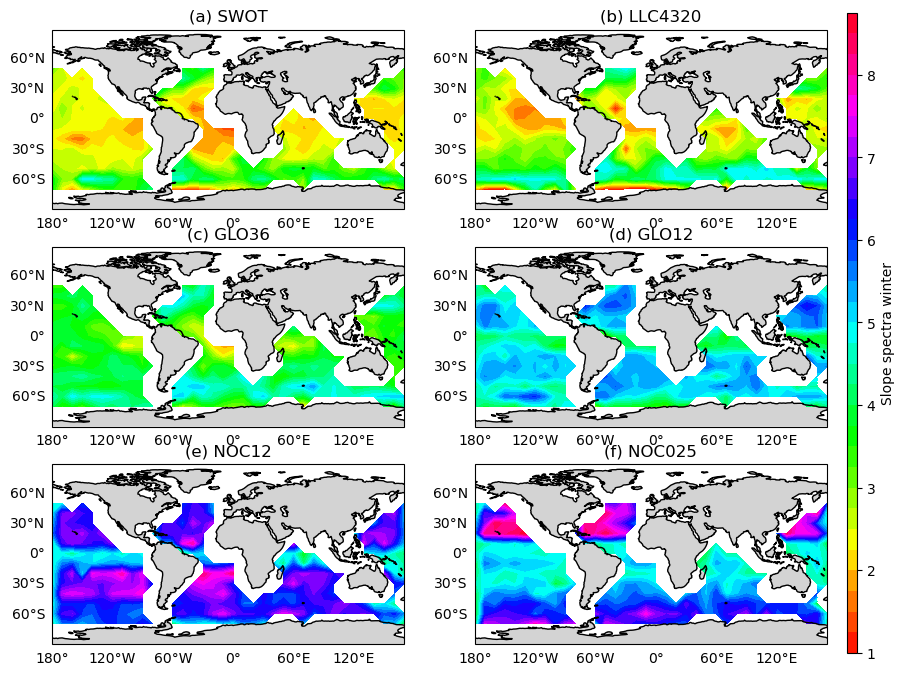

In [14]:
# plotiong seasonal summer mean slope

model= ["GLO12","GLO36","GLO36-DETIDED","NOC12","NOC025","LLC4320","SWOT"]
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)
lon_edges2,lat_edges2 = np.meshgrid(lon_edges[:-1],lat_edges[:-1])

valmin=1
valmax=9
fig, ax = plt.subplots(3, 2,figsize=(10, 8),subplot_kw={'projection': ccrs.PlateCarree()})
fig.subplots_adjust(wspace=0.2, hspace=0.2)
#ax = plt.axes(projection=ccrs.PlateCarree())
imodel=6
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeS2,valmin,valmax,model,0,0,'(a) ')
imodel=5
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeS2,valmin,valmax,model,0,1,'(b) ')
imodel=1
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeS2,valmin,valmax,model,1,0,'(c) ')
imodel=0
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeS2,valmin,valmax,model,1,1,'(d) ')
imodel=3
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeS2,valmin,valmax,model,2,0,'(e) ')
imodel=4
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,m_slopeS2,valmin,valmax,model,2,1,'(f) ')



#plt.colorbar(mesh, ax=ax[0,0], orientation="vertical")
cbar_ax = fig.add_axes([0.92, 0.1, 0.01, .8])
cbar = fig.colorbar(mesh,cax=cbar_ax, orientation='vertical', fraction=0.03,  extend='both')
cbar.set_label("Slope spectra winter")
plt.savefig("FigV2/slope_season_model_summer_{}-{}.png".format(min_wavelength,max_wavelength),dpi=300,transparent=False)
plt.show()



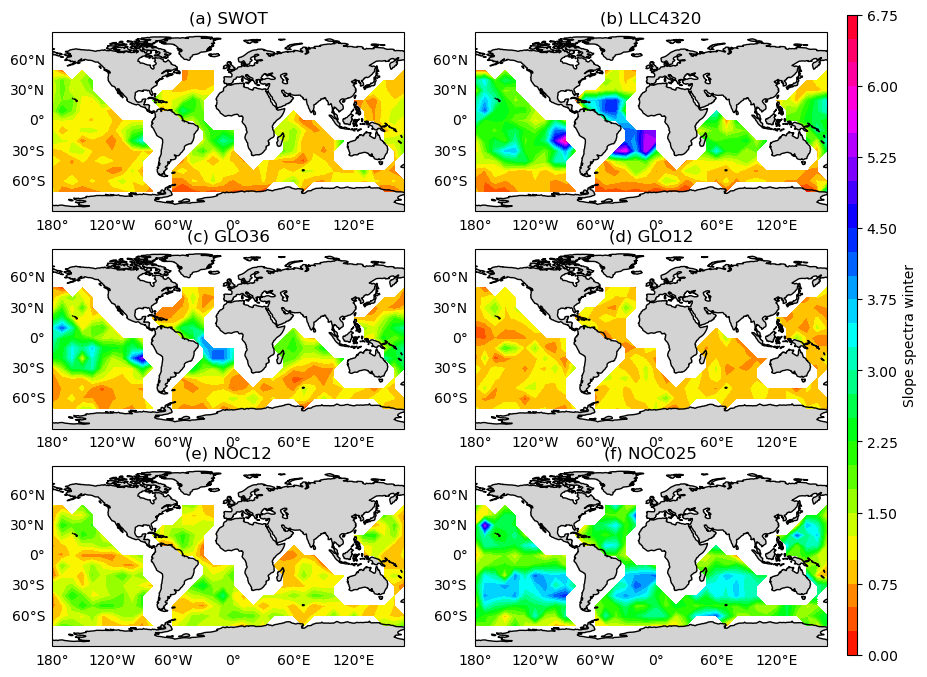

In [15]:
# plotiong seasonal summer std slope

model= ["GLO12","GLO36","GLO36-DETIDED","NOC12","NOC025","LLC4320","SWOT"]
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)
lon_edges2,lat_edges2 = np.meshgrid(lon_edges[:-1],lat_edges[:-1])

valmin=0
valmax=7
fig, ax = plt.subplots(3, 2,figsize=(10, 8),subplot_kw={'projection': ccrs.PlateCarree()})
fig.subplots_adjust(wspace=0.2, hspace=0.2)
#ax = plt.axes(projection=ccrs.PlateCarree())
imodel=6
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeS2,valmin,valmax,model,0,0,'(a) ')
imodel=5
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeS2,valmin,valmax,model,0,1,'(b) ')
imodel=1
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeS2,valmin,valmax,model,1,0,'(c) ')
imodel=0
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeS2,valmin,valmax,model,1,1,'(d) ')
imodel=3
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeS2,valmin,valmax,model,2,0,'(e) ')
imodel=4
ax, mesh=plot_fig(ax,imodel,lon_edges2,lat_edges2,s_slopeS2,valmin,valmax,model,2,1,'(f) ')



#plt.colorbar(mesh, ax=ax[0,0], orientation="vertical")
cbar_ax = fig.add_axes([0.92, 0.1, 0.01, .8])
cbar = fig.colorbar(mesh,cax=cbar_ax, orientation='vertical', fraction=0.03,  extend='both')
cbar.set_label("Slope spectra winter")
plt.savefig("FigV2/std_slope_season_model_summer_{}-{}.png".format(min_wavelength,max_wavelength),dpi=300,transparent=False)
plt.show()

